Chapters 9 to 15 built forecasts from models with an explicit structure: an ARIMA equation, a sum of trees on calendar features, or Prophet's trend plus seasonalities. In this chapter, we start a new family of models, **neural networks**. A neural network is a flexible nonlinear function with many parameters, which it learns from input-output examples. It makes few assumptions about the shape of the relationship, and with enough units, it can approximate any continuous function.

# Learning objectives

In this lecture, we will cover the following topics:

- Windowed approaches and nonlinear models for time series forecasting.
- Neural networks and the Multi-Layer Perceptron (MLP).
- A overview of `MLPRegressor` for MLP.

# Setup

Modules and functions used in this lecture.

| Module | Used for |
|---|---|
| `numpy` | `tanh`, `maximum`, `exp`, `random.default_rng`, `lib.stride_tricks.sliding_window_view` |
| `pandas` | `read_csv`, `pivot_table`, `resample`, `DataFrame` |
| `matplotlib.pyplot` | `subplots`, `plot`, `scatter`, 3-D axes |
| `time` | `perf_counter` -- timing the fits |
| `sklearn.datasets` | `make_circles` -- a toy data set that no straight line can separate |
| `sklearn.preprocessing` | `StandardScaler` -- standardizing the inputs |
| `sklearn.linear_model` | `LinearRegression` -- the linear windowed forecaster |
| `sklearn.neural_network` | `MLPRegressor` -- the Multi-Layer Perceptron |

The neural networks of this chapter come from **scikit-learn**, which is already in the course environment. Deep-learning libraries (PyTorch, TensorFlow) are not needed for an MLP of this size.

In [ ]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor

Self-defined functions carried over from earlier chapters: the run-sequence plot (Chapter 4) and the MSE (Chapter 6).

In [2]:
def run_sequence_plot(y, x=None, title="", xlabel="time", ylabel="value",
                      ax=None, figsize=(9, 3), color="blue", **kwargs):
    "Plot a series against time and return the axes."
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if x is None:
        x = getattr(y, "index", np.arange(len(y)))
    ax.plot(x, y, color=color, lw=1, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    return ax


def mse(observations, estimates):
    "Mean squared error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    if observations.shape != estimates.shape:
        raise ValueError(f"shape mismatch: {observations.shape} vs {estimates.shape}")
    return np.mean((observations - estimates) ** 2)

---

# Windowed approaches for prediction

A **windowed** forecaster uses a fixed window of size $P$.

Use the last $P$ observations within the window $x(t-P+1), \dots, x(t-1), x(t)$, to compute the forecast $\hat x(t+\tau)$, where $\tau$ is the **forecast horizon**. 

As the window slides along the series, it produces a new forecast at every step. Different algorithms differ only in how they combine the $P$ values in the window.

<img src="media/nn/windowed.png" style="width: 45%; display: block; margin: auto;">

For example, the AR($P$) model of order $P$ in Chapters 9 and 10 combines the window linearly,

$$\hat x(t+1) = \beta_0 + \beta_1 x(t) + \beta_2 x(t-1) + \dots + \beta_P x(t-P+1),$$

where the coefficients $\beta_0, \dots, \beta_P$ are estimated from the training data and stay the same for every window.

<img src="media/nn/sin.gif" style="width: 45%; display: block; margin: auto;">


## Limits of linear models

- Linear models are widely used for their simplicity and interpretiveness. 
- However, they assume a constant relationship between input and target variables.
- As such, they cannot capture these nonlinearities and interactions effectively. 

## Advantages of Nonlinear Models

**Nonlinear models**, such as neural networks, support vector machines and tree ensembles (Chapter 14), etc..., can:

  - model the nonlinear relationships between demand and factors, e.g., temperature, capturing the U-shaped curve accurately,
  - take into account the interactions between different variables, such as the combined effect of time, holidays, and temperature on demand,
  - adapt to various patterns and changes in trends over time, making them more robust in dynamic environments.



---

# Neural networks

Neural networks are **universal approximators**: with enough hidden units, a network with a single hidden layer can approximate any continuous function on a bounded domain as closely as we like. The basic idea is to

1. map the data into a new, often higher-dimensional space,
2. through a nonlinear transformation,
3. so that, in the new space, the problem becomes linear (a straight line, or a plane, separates the classes or fits the target).

## Multi-Layer Perceptron

A **Multi-Layer Perceptron (MLP)** is the basic feed-forward neural network. It has at least three layers of nodes (units): 

- an input layer,
- one or more hidden layers, and
- an output layer. 

The nodes in the a hidden layers apply a **nonlinear activation function** $\sigma$. MLP are generally trained with a **supervised learing** technique, i.e., backpropagation.
  
The layers are **fully connected**: each unit receives the outputs of all the units of the previous layer, each with its own weight. The first layer receives the input, and the output of each layer is the input of the next, until the last layer produces the output of the network.

For example, an MLP has two hidden layers of $h_1$ and $h_2$ units, inputs of size $d_\text{in}$ and outputs of size $d_\text{out}$.

<img src="media/nn/mlp.png" style="width: 45%; display: block; margin: auto;">

- **Input layer.** It has $d_\text{in}$ units, one per input variable, and passes the input vector $\mathbf{x} \in \mathbb{R}^{d_\text{in}}$ on without transforming it.
- **First hidden layer.** Each of its $h_1$ units is connected to all $d_\text{in}$ inputs. The layer multiplies the input by a weight matrix $W_\text{in} \in \mathbb{R}^{d_\text{in} \times h_1}$, adds a bias vector, and applies a nonlinear **activation function** $\sigma$ to each element:
$$\mathbf{z}_1 = \sigma\big(W_\text{in}^\top \mathbf{x} + \mathbf{b}_1\big) \in \mathbb{R}^{h_1}.$$
- **Second hidden layer.** It does the same with the $h_1$ outputs of the first layer, with its own weights $W_{h_{1,2}} \in \mathbb{R}^{h_1 \times h_2}$:
$$\mathbf{z}_2 = \sigma\big(W_{h_{1,2}}^\top \mathbf{z}_1 + \mathbf{b}_2\big) \in \mathbb{R}^{h_2}.$$
- **Output layer.** It combines the $h_2$ outputs of the second hidden layer into the $d_\text{out}$ outputs. The activation of the output layer depends on the task: none (the identity) for regression, a softmax for classification:
$$\hat{\mathbf{y}} = W_\text{out}^\top \mathbf{z}_2 + \mathbf{b}_3 \in \mathbb{R}^{d_\text{out}}.$$

The weight matrices and bias vectors are the **trainable parameters** of the model. Without the activation function $\sigma$, the three layers would collapse into a single matrix product, and the MLP would be a linear regression. The activation function $\sigma$ is what makes the network nonlinear. The three common choices are the **Rectified Linear Unit (ReLU)** $\max(0, a)$, the hyperbolic tangent $\tanh(a)$, and the logistic sigmoid $1/(1+e^{-a})$.

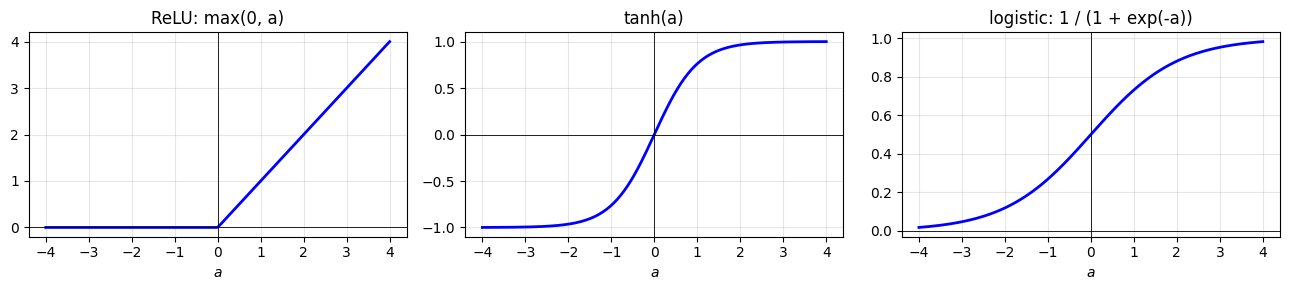

In [6]:
a = np.linspace(-4, 4, 200)
activations = {"ReLU: max(0, a)": np.maximum(0, a),
               "tanh(a)": np.tanh(a),
               "logistic: 1 / (1 + exp(-a))": 1 / (1 + np.exp(-a))}

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, (name, values) in zip(axes, activations.items()):
    ax.plot(a, values, color="blue", lw=2)
    ax.axhline(0, color="black", lw=0.6); ax.axvline(0, color="black", lw=0.6)
    ax.set(title=name, xlabel="$a$")
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The forward pass is only a few matrix products. Below, we write it in NumPy for the network of the figure ($d_\text{in} = 3$, $h_1 = 5$, $h_2 = 6$, $d_\text{out} = 2$) with random weights, and count its parameters.

In [7]:
rng = np.random.default_rng(8990)
sizes = [3, 5, 6, 2]                                    # d_in, h1, h2, d_out
weights = [rng.normal(0, 1, (m, n)) for m, n in zip(sizes[:-1], sizes[1:])]
biases = [np.zeros(n) for n in sizes[1:]]

def mlp_forward(x, weights, biases, sigma=np.tanh):
    "Forward pass of an MLP: sigma on every hidden layer, identity on the output layer."
    z = x
    for W, b in zip(weights[:-1], biases[:-1]):
        z = sigma(W.T @ z + b)
    return weights[-1].T @ z + biases[-1]

x = np.array([0.5, -1.0, 2.0])
print("output:", mlp_forward(x, weights, biases).round(3))
for W, b in zip(weights, biases):
    print(f"layer {W.shape[0]} -> {W.shape[1]}: {W.size} weights + {b.size} biases")
print("total parameters:", sum(W.size + b.size for W, b in zip(weights, biases)))

output: [ 0.756 -2.178]
layer 3 -> 5: 15 weights + 5 biases
layer 5 -> 6: 30 weights + 6 biases
layer 6 -> 2: 12 weights + 2 biases
total parameters: 70


A layer from $m$ to $n$ units has $m \times n$ weights and $n$ biases, so even this small network has 70 parameters. The number grows with the product of neighboring layer sizes, which is why MLPs need more data than the models of the earlier chapters.

## Training an MLP

An MLP is trained by **supervised learning**: we give it input-output pairs $\{\mathbf{x}_i, \mathbf{y}_i\}$, and it adapts its weights so that its prediction $\hat{\mathbf{y}}_i$ comes close to the desired output $\mathbf{y}_i$. Closeness is measured by a **loss function** $\mathcal{L}$. For regression, the usual loss is the MSE over the training pairs, often with a small penalty $\alpha \lVert W \rVert^2$ on the weights.

The loss is minimized by **gradient descent**. Each step moves every weight a small amount against the gradient of the loss,

$$W \leftarrow W - \delta \, \frac{\partial \mathcal{L}}{\partial W},$$

where $\delta$ is the **learning rate**. The gradient with respect to all the weights is computed by **backpropagation**: the chain rule applied layer by layer, from the output back to the input. In practice, each step uses the gradient on a small random **mini-batch** of pairs (stochastic gradient descent), and modern optimizers adapt the step size for each weight. The most popular one is **Adam** (adaptive moment estimation), which keeps running averages of the gradient and of its square. One pass over all the training pairs is an **epoch**.

The loss of an MLP is not convex. Gradient descent finds a local minimum that depends on the random initial weights, so two fits with different seeds give different networks. 

---

# MLP for time series forecasting

- The MLP can be used as a windowed technique for time series forecasting.
- The sequence of past values $x(t-P), \dots, x(t-1), x(t)$ represents the input ($d_\text{in} = P$).
- $x(t+\tau)$ is be the output that the model learns to predict ($d_\text{out} = 1$).
- We can also train the MLP to predict a sequence of $d_\text{out} = H+1$ future predictions, e.g., $x(t+\tau), x(t+\tau+1), \dots, x(t+\tau+H)$.

<img src="media/nn/mlp_windowed.png" style="width: 45%; display: block; margin: auto;">

- Key for the training of the MLP is the creation of input-output pairs $\{\mathbf{x}_i, \mathbf{y}_i\}$ used for training. Given the input $\mathbf{x}_i$ the model must learn to predict the output $\mathbf{y}_i$.
- This is done by adapting the model weight matrices and bias vectors to minimize the discrepancy between the prediction $\mathbf{\hat y}_i$ and the desired output $\mathbf{y}_i$.
- The weights are modified according to the gradient taken with respect to a loss function $\mathcal{L}(\mathbf{\hat y}_i, \mathbf{y}_i)$ such as the MSE, e.g., $W \leftarrow W - \delta \frac{\partial \mathcal{L}}{\partial W}$.
- $\delta$ is a small constant defining the gradient step (learning rate).

- Given the chunk of time series used for training, the training samples are generated according to the scheme in the figure below.
- Each input-output pair consists of:
    - a window of past time series values $x(t-P), \dots, x(t-1), x(t)$.
    - a window of future values $x(t+\tau), x(t+\tau+1) \dots, x(t+\tau+H)$.

<img src="media/nn/data_split.png" style="width: 100%; display: block; margin: auto;">

## The Rome electricity load

Our series is the electricity consumption measured on a backbone of the power distribution network of Rome. The original series has a 10-minute resolution. The file `data/elec_rome_hourly.csv` holds its hourly averages, which are smoother and easier to predict. The source does not give the dates or the unit of the measurements, so we index the series by the hour number (`step`) and report the load in the units of the file. To keep the fits fast, we use the first 3,000 hours (125 days) only.

hours in the file: 22896,  used: 3000


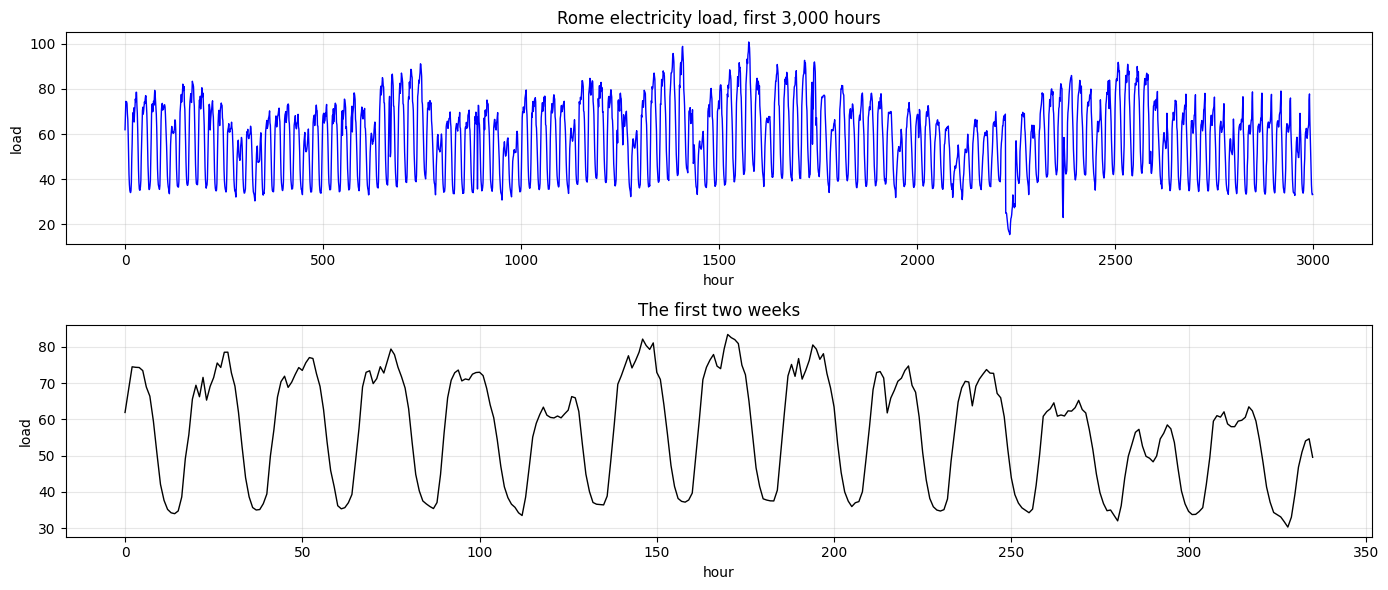

In [9]:
rome = pd.read_csv("data/elec_rome_hourly.csv", index_col="step")["load"]
time_series = rome.to_numpy()[:3000]
print(f"hours in the file: {len(rome)},  used: {len(time_series)}")

fig, axes = plt.subplots(2, 1, figsize=(14, 6))
run_sequence_plot(time_series, ax=axes[0], title="Rome electricity load, first 3,000 hours",
                  xlabel="hour", ylabel="load")
run_sequence_plot(time_series[:336], ax=axes[1], color="black", xlabel="hour", ylabel="load",
                  title="The first two weeks")
plt.tight_layout(); plt.show()

The load follows a strong daily cycle, with a lower level on some days of each week and a few sudden drops. The daily cycle makes 24 hours the natural seasonal period.

We keep the first 90% of the hours (2,700) for training and the last 300 hours (12.5 days) for testing.

In [10]:
n_train = int(0.9 * len(time_series))
print(f"training hours: 0-{n_train - 1},  test hours: {n_train}-{len(time_series) - 1}")

training hours: 0-2699,  test hours: 2700-2999


## Input-output windows

New self-defined functions in this chapter: `create_windows`, which cuts a series into input-output pairs, and `split_windows`, which assigns each pair to the training or the test set by the time of its target.

In [ ]:
def create_windows(data, window_size, forecast_horizon):
    """Input windows x(t-P+1), ..., x(t) and output windows x(t+1), ..., x(t+H).

    Row i of X holds data[i : i+P]; row i of Y holds data[i+P : i+P+H].
    """
    data = np.asarray(data, dtype=float)
    n = len(data) - window_size - forecast_horizon + 1
    windows = np.lib.stride_tricks.sliding_window_view(data, window_size + forecast_horizon)[:n]
    return windows[:, :window_size].copy(), windows[:, window_size:].copy()


def split_windows(X, y, window_size, forecast_horizon, n_train):
    """Split window pairs in time order: a pair is a training pair if its LAST target lies
    before position n_train, and a test pair otherwise."""
    target_pos = np.arange(len(X)) + window_size + forecast_horizon - 1
    train = target_pos < n_train
    return X[train], y[train], X[~train], y[~train]

`create_windows` cuts the series into pairs with input windows of size $P$ (`window_size`) and output windows of size $H$ (`forecast_horizon`). We first look at windows with $P = 12$ and $H = 12$. If we want a single forecast $\tau = 12$ steps ahead, we take only the last element of each output window.

We cut the **whole** series and then split the pairs by the time of their last target with `split_windows`. A pair is a training pair only if its whole output window lies in the training period. Every hour of the test period is the target of exactly one test pair, and the inputs of the first test pairs may come from the end of the training period, as they would in real forecasting.

pairs: (2977, 12) (2977, 12)   training: (2677, 12)   test: (300, 12)


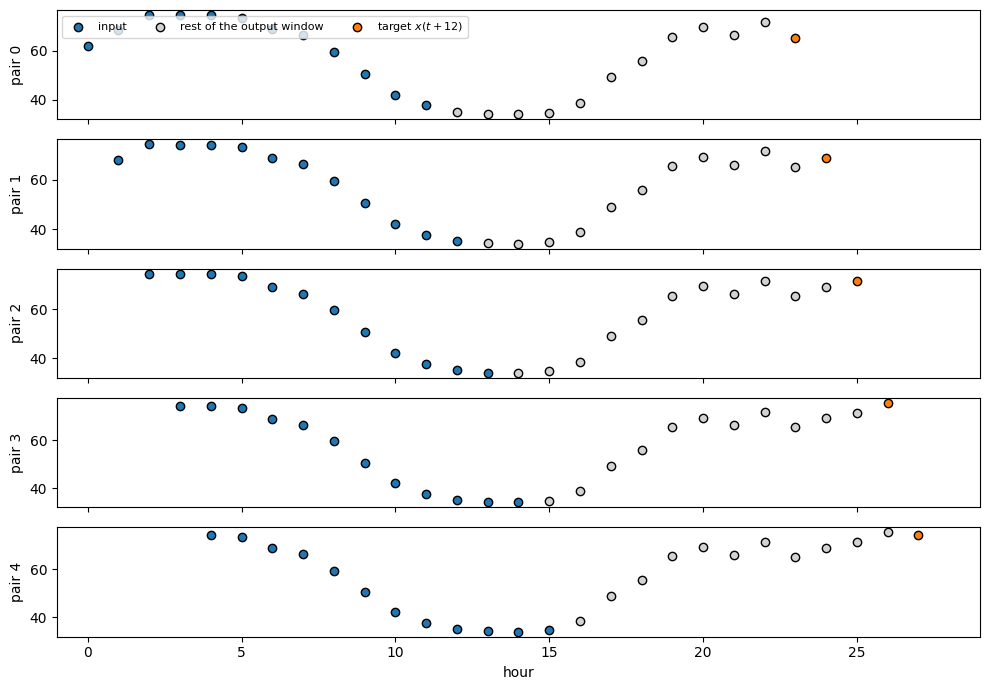

In [11]:
window_size, forecast_horizon = 12, 12
X, Y = create_windows(time_series, window_size, forecast_horizon)
X_train, Y_train, X_test, Y_test = split_windows(X, Y, window_size, forecast_horizon, n_train)
print("pairs:", X.shape, Y.shape, "  training:", X_train.shape, "  test:", X_test.shape)

fig, axes = plt.subplots(5, 1, figsize=(10, 7), sharex=True)
for i, ax in enumerate(axes):
    ax.scatter(range(i, i + window_size), X_train[i], color="tab:blue", edgecolor="k", label="input")
    ax.scatter(range(i + window_size, i + window_size + forecast_horizon - 1), Y_train[i, :-1],
               color="lightgray", edgecolor="k", label="rest of the output window")
    ax.scatter(i + window_size + forecast_horizon - 1, Y_train[i, -1], color="tab:orange",
               edgecolor="k", label="target $x(t+12)$")
    ax.set(xlim=(-1, 29), ylabel=f"pair {i}")
axes[0].legend(ncol=3, fontsize=8, loc="upper left")
axes[-1].set_xlabel("hour")
plt.tight_layout(); plt.show()

Each row is one pair: the blue points are the input window $x(t-11), \dots, x(t)$, and the orange point is the target $x(t+12)$. The next pair is the same picture shifted by one hour.

A more realistic task is to forecast the load one day ahead from the last 12 hours. We set `forecast_horizon = 24` and keep only the last element of each output window, so the target is $x(t+24)$.

In [12]:
window_size, forecast_horizon = 12, 24
X, Y = create_windows(time_series, window_size, forecast_horizon)
X_train, Y_train, X_test, Y_test = split_windows(X, Y, window_size, forecast_horizon, n_train)
y_train, y_test = Y_train[:, -1], Y_test[:, -1]          # only the last step of the horizon
print("training pairs:", X_train.shape, "  test pairs:", X_test.shape)

training pairs: (2665, 12)   test pairs: (300, 12)


## Standardizing the inputs

Neural networks train best when their inputs lie in a small range around zero. With large raw inputs, the units start in the flat parts of their activations, and the gradient steps are badly scaled. We standardize the windows with `StandardScaler`:

- `scaler.fit_transform(X_train)` subtracts from each column of `X_train` its mean and divides it by its standard deviation;
- `scaler.transform(X_test)` subtracts the **training** mean and divides by the **training** standard deviation.

We do not use the test statistics, because at forecast time we do not have the test data. Using them would leak information from the future into the forecast.

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("training means of the first three columns:", scaler.mean_[:3].round(2))

training means of the first three columns: [58.27 58.27 58.26]


## Fitting the MLP

`MLPRegressor(hidden_layer_sizes, activation, solver, max_iter, random_state)` is a scikit-learn estimator that implements a MLP neural network for regression tasks. 

- `hidden_layer_sizes=(h1, h2, ...)` is hidden layer sizes.
- `activation` is the activation function for the hidden layer. Common selections:
    - `relu` (default): Rectified Linear Unit function, great for general non-linear modeling.
    - `tanh`: Hyperbolic tan function, returning values between -1 and 1.
    - `logistic`: Logistic sigmoid function, returning values between 0 and 1.
    - `identity`: No-op activation, returning linear outputs.
- `solver` is the optimization algorithm used to weight updates and minimize loss. Common selections:
    - `adam` (default): Stochastic gradient optimizer that works very well on relatively large datasets with thousands of samples or more.
    - `lbfgs`: An optimizer in the family of quasi-Newton methods, which converges faster and performs better on smaller datasets.
    - `sgd`: Stochastic gradient descent.
- `max_iter` is is the maximum number of epochs (iterations through the training data). Common selections: Default is 200. For complex networks or large datasets, this often needs to be increased (e.g., 1000 or 2000) to ensure convergence.
- `random_state` determines the random seed for weight and bias initialization as well as data shuffling. Common selections: An integer (e.g., 0 or 42) to ensure reproducibility across runs, or None for random initialization every time.

We use two hidden layers with $h_1 = 16$ and $h_2 = 8$ units and the ReLU activation, and we train with Adam for at most 2,000 epochs. Larger layers, or more of them, increase the capacity, and with it the risk of overfitting. `MLPRegressor` stops earlier when the training loss improves by less than its tolerance for 10 epochs in a row. We fix `random_state` so that the initial weights, and therefore the result, are reproducible.

stopped after 401 epochs in 2.0 s
parameters: 353


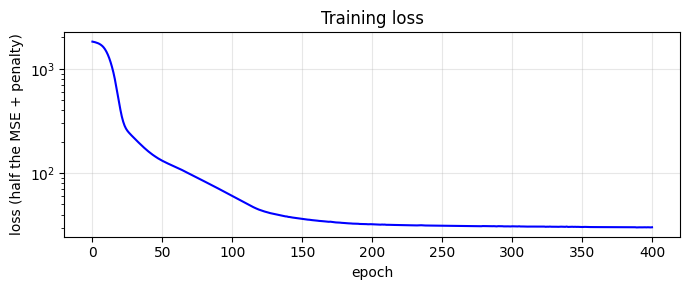

In [14]:
mlp = MLPRegressor(hidden_layer_sizes=(16, 8), activation="relu", solver="adam",
                   max_iter=2000, random_state=0)
start = time.perf_counter()
mlp.fit(X_train_scaled, y_train)
print(f"stopped after {mlp.n_iter_} epochs in {time.perf_counter() - start:.1f} s")
print("parameters:", sum(W.size for W in mlp.coefs_) + sum(b.size for b in mlp.intercepts_))

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(mlp.loss_curve_, color="blue")
ax.set(yscale="log", title="Training loss", xlabel="epoch", ylabel="loss (half the MSE + penalty)")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The training loss falls fast in the first tens of epochs and then slowly flattens. scikit-learn reports half the MSE, plus a small $L_2$ penalty on the weights (`alpha = 0.0001`).

Once the model is trained, we compute the forecasts of the test period. We can also forecast beyond the data: the last 12 hours of the series give the forecast of the load 24 hours after the end of the series. We cannot check that forecast, since its target is unknown. That is the real forecasting situation.

In [15]:
y_pred = mlp.predict(X_test_scaled)

last_window = time_series[-window_size:].reshape(1, -1)
next_day = mlp.predict(scaler.transform(last_window))[0]
print(f"forecast for hour {len(time_series) - 1 + forecast_horizon}: {next_day:.2f}")

forecast for hour 3023: 34.79


To check the model, we compute the MSE on the test period and plot the forecasts against the data.

MLP test MSE: 23.51


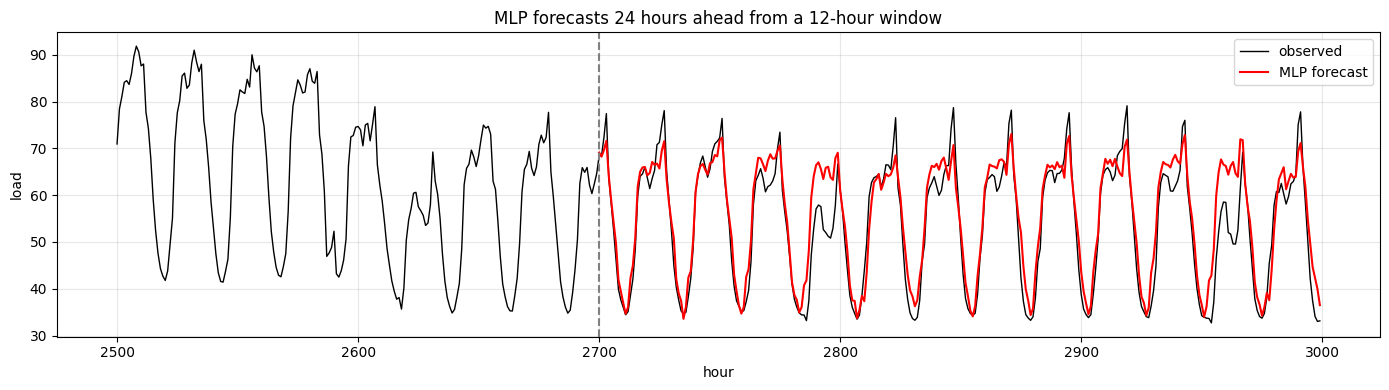

In [16]:
test_hours = np.arange(n_train, len(time_series))
print(f"MLP test MSE: {mse(y_test, y_pred):.2f}")

ax = run_sequence_plot(time_series[2500:], x=np.arange(2500, len(time_series)), color="black",
                       figsize=(14, 4), label="observed", xlabel="hour", ylabel="load",
                       title="MLP forecasts 24 hours ahead from a 12-hour window")
ax.plot(test_hours, y_pred, color="red", lw=1.5, label="MLP forecast")
ax.axvline(n_train, color="gray", ls="--")
ax.legend(); plt.tight_layout(); plt.show()

The forecasts follow the daily cycle, but is the forecast good?

## A benchmark: the seasonal naive forecast

Here, the forecast horizon $\tau = 24$ equals the period of the main seasonality, so the natural benchmark is the seasonal naive forecast of Chapter 6: the load 24 hours ahead equals the load now, $\hat x(t+24) = x(t)$. It is the last value in each input window. A forecasting method that does not beat this benchmark is of no use.

We also fit the linear windowed forecaster, the AR-type regression of $x(t+24)$ on the same 12 values, to separate the effect of the nonlinearity from the effect of the inputs.

seasonal naive  MSE: 22.29
linear window   MSE: 25.90
MLP (16, 8)     MSE: 23.51


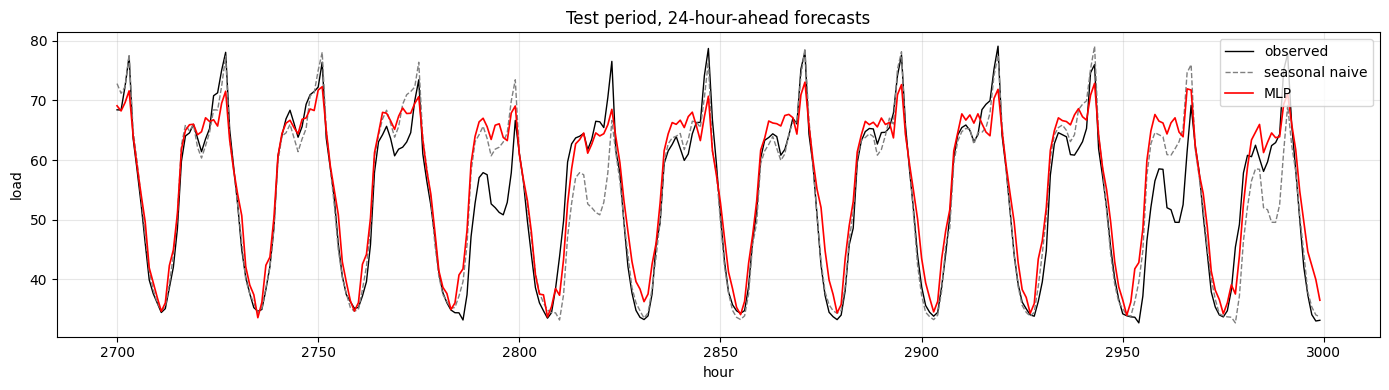

In [17]:
y_naive = X_test[:, -1]                                   # x(t): same hour yesterday
linear = LinearRegression().fit(X_train, y_train)
y_linear = linear.predict(X_test)

print(f"seasonal naive  MSE: {mse(y_test, y_naive):.2f}")
print(f"linear window   MSE: {mse(y_test, y_linear):.2f}")
print(f"MLP (16, 8)     MSE: {mse(y_test, y_pred):.2f}")

ax = run_sequence_plot(y_test, x=test_hours, color="black", figsize=(14, 4), label="observed",
                       xlabel="hour", ylabel="load", title="Test period, 24-hour-ahead forecasts")
ax.plot(test_hours, y_naive, color="gray", lw=1, ls="--", label="seasonal naive")
ax.plot(test_hours, y_pred, color="red", lw=1.2, label="MLP")
ax.legend(); plt.tight_layout(); plt.show()

On this test period, the MLP (MSE 23.51) does **not** beat the seasonal naive forecast (22.29). It is better than the linear model on the same 12 inputs (25.90), so the nonlinearity helps, but 12 hours of history are not enough to beat simply repeating yesterday.

The plot shows where the errors come from. Twice in the test period, around hours 2790 and 2955, the load stays low for a whole day: a low day of the weekly cycle. A 12-hour window cannot see the week, so the MLP forecasts an ordinary day. The seasonal naive forecast misses the same days, and then also the following day, when it repeats the low day (around hours 2815 and 2980).

## The effect of the seed

The loss of the MLP is not convex, so the fitted network depends on its random initial weights. We refit the same architecture with five seeds.

In [18]:
seed_mse = []
for seed in range(5):
    net = MLPRegressor(hidden_layer_sizes=(16, 8), activation="relu", solver="adam",
                       max_iter=2000, random_state=seed).fit(X_train_scaled, y_train)
    seed_mse.append(mse(y_test, net.predict(X_test_scaled)))
print("test MSE by seed:", np.round(seed_mse, 2))
print(f"mean {np.mean(seed_mse):.2f}, range {np.min(seed_mse):.2f}-{np.max(seed_mse):.2f}")

test MSE by seed: [23.51 24.   27.63 24.89 23.78]
mean 24.76, range 23.51-27.63


The test MSE ranges from 23.51 to 27.63 across the seeds, a spread larger than the gap between the MLP and the benchmark. Seed 0, used above, happens to be the best of the five, and none of them beats the seasonal naive forecast. A single fit can make a network look better or worse than it is, so we should report several seeds, or average their forecasts.

---

# Choosing the window size

## Drawbacks of a fixed window

The window size $P$ is the memory of a windowed forecaster: the model cannot use anything older than $P$ steps. That raises two questions.

- What is the best value of $P$?
- If $P$ is fixed, how can the model handle dependencies of different lengths?

Think of predicting the next word in a sentence.

<img src="media/nn/word_pred.gif" style="width: 55%; display: block; margin: auto;">

In the first sentence, the word we need lies 4 steps back. In the second, it lies 9 steps back. A model with a fixed window must make $P$ as large as the longest memory it will ever need. A larger window means more inputs, more weights to estimate from the same data, and slower training, while most of the inputs are irrelevant most of the time.

For the load series, we can try a few window sizes directly. Besides $P = 12$, we use one day ($P = 24$), two days ($P = 48$) and one week ($P = 168$), each with the linear window model and three MLP seeds. The test targets are the same 300 hours for every $P$.

In [19]:
rows = []
start = time.perf_counter()
for P in [12, 24, 48, 168]:
    X, Y = create_windows(time_series, P, forecast_horizon)
    Xtr, Ytr, Xte, Yte = split_windows(X, Y, P, forecast_horizon, n_train)
    ytr, yte = Ytr[:, -1], Yte[:, -1]
    sc = StandardScaler().fit(Xtr)
    mlp_mse = [mse(yte, MLPRegressor(hidden_layer_sizes=(16, 8), activation="relu", solver="adam",
                                     max_iter=2000, random_state=seed)
                       .fit(sc.transform(Xtr), ytr).predict(sc.transform(Xte)))
               for seed in range(3)]
    rows.append({"P": P, "training pairs": len(Xtr),
                 "seasonal naive": mse(yte, Xte[:, -1]),
                 "linear window": mse(yte, LinearRegression().fit(Xtr, ytr).predict(Xte)),
                 "MLP, mean of 3 seeds": np.mean(mlp_mse),
                 "MLP, best seed": np.min(mlp_mse), "MLP, worst seed": np.max(mlp_mse)})
print(f"{time.perf_counter() - start:.0f} s")
window_table = pd.DataFrame(rows).set_index("P").round(2)
window_table

51 s


,training pairs,seasonal naive,linear window,"MLP, mean of 3 seeds","MLP, best seed","MLP, worst seed"
P,,,,,,
12,2665,22.29,25.90,25.05,23.51,27.63
24,2653,22.29,23.08,20.37,18.98,22.69
48,2629,22.29,21.81,18.48,17.14,19.87
168,2509,22.29,12.45,19.80,16.46,22.21


The seasonal naive MSE is the same in every row, because the test targets are the same 300 hours.

- $P = 12$. Neither model beats the benchmark, as we saw above.
- $P = 24$ and $P = 48$. With one or two days of history, the MLP beats the seasonal naive forecast for every seed (mean MSE 20.37 and 18.48), and it stays ahead of the linear model, which only just reaches the benchmark at $P = 48$.
- $P = 168$. With a one-week window, the **linear** model is the best of all models in the table (MSE 12.45, about 44% below the benchmark). The window now contains the load at the same hour one week before the target, and the weekly cycle, with its low days, becomes a linear pattern. The MLP does not profit: its mean MSE (19.80) is worse than at $P = 48$, and the spread across seeds widens (16.46 to 22.21). Its first layer alone now has $168 \times 16 = 2{,}688$ weights, and the whole network about 2,850 parameters, estimated from 2,509 training pairs.

The lesson is that the choice of inputs mattered more than the nonlinearity. With the right window, a linear model was enough. A network has to learn the same structure from many more weights, which needs more data than 2,500 hourly pairs. The test period is also short (12.5 days, about two weekly cycles), so differences of one or two MSE units are within the seed-to-seed spread.

---

# Summary

**Windowed forecaster**: $\ \hat x(t+\tau) = g\big(x(t-P+1), \dots, x(t)\big)$. The AR($P$) model is the linear case; an MLP makes $g$ nonlinear.

- **Why nonlinear models.** Linear models cannot follow U-shaped effects (demand against temperature) or interactions (temperature by day type) unless we build the right features by hand. Neural networks learn them.
- **MLP.** Fully connected layers, $\mathbf{z}_{k} = \sigma(W_k^\top \mathbf{z}_{k-1} + \mathbf{b}_k)$, with a nonlinear activation (ReLU, tanh, logistic) on the hidden layers and none on the output for regression. A layer from $m$ to $n$ units has $mn + n$ parameters.
- **Training.** Minimize the MSE by gradient descent, $W \leftarrow W - \delta\, \partial\mathcal{L}/\partial W$, with the gradients from backpropagation, on mini-batches, usually with Adam. The loss is not convex, so the result depends on the random initial weights: check several seeds.
- **Forecasting workflow.** Cut the series into input-output windows, split them by the time of the target, standardize with training statistics only, fit, and compare with the seasonal naive forecast and with a linear model on the same window.
- **The window is the memory.** With 12 hours of history, no model beat the seasonal naive forecast; the MLP did with one or two days. With a one-week window, a linear model was the best (MSE 12.45 against 22.29 for the benchmark), because the information it needs, the same hour a week earlier, is in the window. The MLP, with about 2,850 parameters estimated from 2,509 pairs, gained nothing from it. A fixed window forces us to guess the longest memory the problem needs.

In Chapter 17, we replace the fixed window by a **recurrent neural network**, which carries a memory of the whole past in a hidden state, and we meet the echo state network, a recurrent network that trains in about a second.